# **FEATURE ENGINEERING**

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df_engineering = pd.read_csv("/content/Stroke__Risk_Prediction_Cleaned_Inspected_.csv")

In [ ]:
df_engineering.shape

(3265, 12)

In [ ]:
df_engineering.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3265 entries, 0 to 3264
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 3265 non-null   int64  
 1   gender             3265 non-null   object 
 2   age                3265 non-null   float64
 3   hypertension       3265 non-null   int64  
 4   heart_disease      3265 non-null   int64  
 5   ever_married       3265 non-null   object 
 6   work_type          3265 non-null   object 
 7   Residence_type     3265 non-null   object 
 8   avg_glucose_level  3265 non-null   float64
 9   bmi                3265 non-null   float64
 10  smoking_status     3265 non-null   object 
 11  stroke             3265 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 306.2+ KB


## **1. GENDER**

Based on research, while biology is constant, national data shows that ***Filipino men often have higher smoking rates and untreated hypertension, while Filipino women are seeing rising obesity rates***.

It is seen that F**ilipino men are more at risk than women.**


Therefore, we classify:

* **0: Female (lower risk)**

* **1: Male (higher risk)**

In [ ]:
gender_unique_value = df_engineering['gender'].unique()
print(gender_unique_value)

['Male' 'Female']


In [ ]:
df_engineering["gender_score_risk"] = df_engineering["gender"].map({"Female": 0, "Male": 1})

## **2. AGE**

Scope of our study: **ages 35-90**

* **1:** Increasing Trend / Early Risk (Ages 35 to 54)
* **0:** Declining/Stabilizing Trend Range (Ages 55 to 90)

In [ ]:
df_engineering["age_score_risk"] = pd.cut(df_engineering["age"],
                                          bins=[34, 54, 90],
                                          labels=[0, 1]).astype(int)

## **3. AVERAGE GLUCOSE LEVEL**

**Clinical Categories:**
* **Normal:** < 140 mg/dL.
* **Prediabetic:** 140 to 199 mg/dL
* **Diabetic:** >= 200 mg/dL


In [ ]:
df_engineering["glucose_score_risk"] = pd.cut(df_engineering["avg_glucose_level"],
                                              bins=[0, 140, 200, np.inf],
                                              labels=[0, 1, 2],
                                              right=False).astype(int)

## **4. BMI**

A BMI of 23 kg/m² or higher is considered a critical threshold for intervention, as it is associated with increased health risks, including obesity-related complications.

* **Level 0: Normal** (< 23).
* **Level 1: Overweight/Obese** (>=23).


In [ ]:
df_engineering["bmi_score_risk"] = pd.cut(df_engineering["bmi"],
                                          bins=[0, 23, np.inf],
                                          labels=[0, 1],
                                          right=False).astype(int)

## **5. SMOKING STATUS**

* **0 (No Active Risk):** never smoked

* **1 (Unrecorded History / Latent Risk):** Unknown

* **2 (Historical Risk):** formerly smoked

* **3 (Highest Active Risk):** smokes

In [ ]:
smokestatus_unique_value = df_engineering['smoking_status'].unique()
print(smokestatus_unique_value)

['formerly smoked' 'never smoked' 'smokes' 'Unknown']


In [ ]:
df_engineering["smoking_score_risk"] = df_engineering["smoking_status"].map({"never smoked": 0, "Unknown": 1, "formerly smoked": 2, "smokes": 3}).astype(int)

## **6. RESIDENCE TYPE**

Regionally, the statistics reveal an uneven distribution of stroke incidence, with urban areas witnessing higher rates. Regions such as Metro Manila and Central Luzon have reported the highest mortality rates linked to strokes, largely due to lifestyle factors, including sedentary behavior, poor diet, and insufficient health access. Conversely, rural areas tend to have lower but still concerning prevalence rates, suggesting disparities in healthcare availability and patient education.

In [ ]:
residence_unique_value = df_engineering['Residence_type'].unique()
print(residence_unique_value)

['Urban' 'Rural']


In [ ]:
df_engineering["residence_score_risk"] = df_engineering["Residence_type"].map({"Rural":1, "Urban":2})

In [ ]:
# drop columns not needed
df_engineering = df_engineering.drop(columns=["ever_married"])
df_engineering = df_engineering.drop(columns=["work_type"])

# **ADDITIONAL:**

In [ ]:
df_frs_hnt = df_engineering.copy()

def calculate_frs_bmi_hnt_points(row):
    age = row['age']
    is_male = (row['gender_score_risk'] == 1) # Male = 1, Female = 0
    smokes = (row['smoking_score_risk'] == 3) # Active smoker proxy
    has_hyper = (row['hypertension'] == 1)    # Diagnosed but untreated baseline (HnT)

    # Gagamitin natin ang glucose level bilang indicator ng Diabetes status (Framingham component)
    has_diabetes = (row['avg_glucose_level'] >= 126.0)

    points = 0

    # 1. AGE POINTS (Framingham Standard)
    if age < 35: points += 0
    elif age < 40: points += 2
    elif age < 45: points += 5 if is_male else 4
    elif age < 50: points += 6 if is_male else 5
    elif age < 55: points += 8 if is_male else 7
    elif age < 60: points += 10 if is_male else 8
    elif age < 65: points += 11 if is_male else 9
    elif age < 70: points += 12 if is_male else 10
    elif age < 75: points += 14 if is_male else 11
    else: points += 15 if is_male else 12

    # 2. SMOKER POINTS
    if smokes:
        points += 4 if is_male else 3

    # 3. HYPERTENSION POINTS (Strictly aligned with FRS-BMI-HnT: Untreated Blood Pressure Proxy)
    if has_hyper:
        points += 3 if is_male else 4
    else:
        points += 0 if is_male else -1

    # 4. DIABETES POINTS
    if has_diabetes:
        points += 3 if is_male else 4

    # 5. BMI POINTS (The Non-Laboratory Core Substitution)
    if row['bmi'] >= 25.0:
        points += 2

    # --- CONVERT POINTS TO VASCULAR AGE (FRS-BMI Standardized Mapping) ---
    if is_male:
        if points <= -1: v_age = 28
        elif points == 0: v_age = 30
        elif points <= 2: v_age = 33
        elif points <= 4: v_age = 37
        elif points <= 6: v_age = 41
        elif points <= 8: v_age = 46
        elif points <= 10: v_age = 52
        elif points <= 12: v_age = 58
        elif points <= 14: v_age = 66
        elif points == 15: v_age = 72
        elif points == 16: v_age = 76
        else: v_age = 82
    else: # Female Mapping
        if points <= 1: v_age = 28
        elif points <= 3: v_age = 32
        elif points <= 5: v_age = 38
        elif points <= 7: v_age = 43
        elif points <= 9: v_age = 49
        elif points <= 11: v_age = 57
        elif points <= 13: v_age = 66
        elif points == 14: v_age = 76
        else: v_age = 82

    return v_age

print("--- INITIATING ADAPTED FRS-BMI-HnT EMBEDDING ---")

# Kalkulahin ang Vascular Age gamit ang FRS-BMI-HnT Model
df_frs_hnt['vascular_age_hnt'] = df_frs_hnt.apply(calculate_frs_bmi_hnt_points, axis=1)

df_engineering['VAAF'] = df_frs_hnt['vascular_age_hnt'] - df_frs_hnt['age']

df_engineering['TGI'] = df_frs_hnt['bmi'] * df_frs_hnt['avg_glucose_level']

--- INITIATING ADAPTED FRS-BMI-HnT EMBEDDING ---


In [ ]:
output_filename = 'Stroke_Prediction_Engineered2.csv'
df_engineering.to_csv(output_filename, index=False)

# **STATISTICAL COMPARISON**

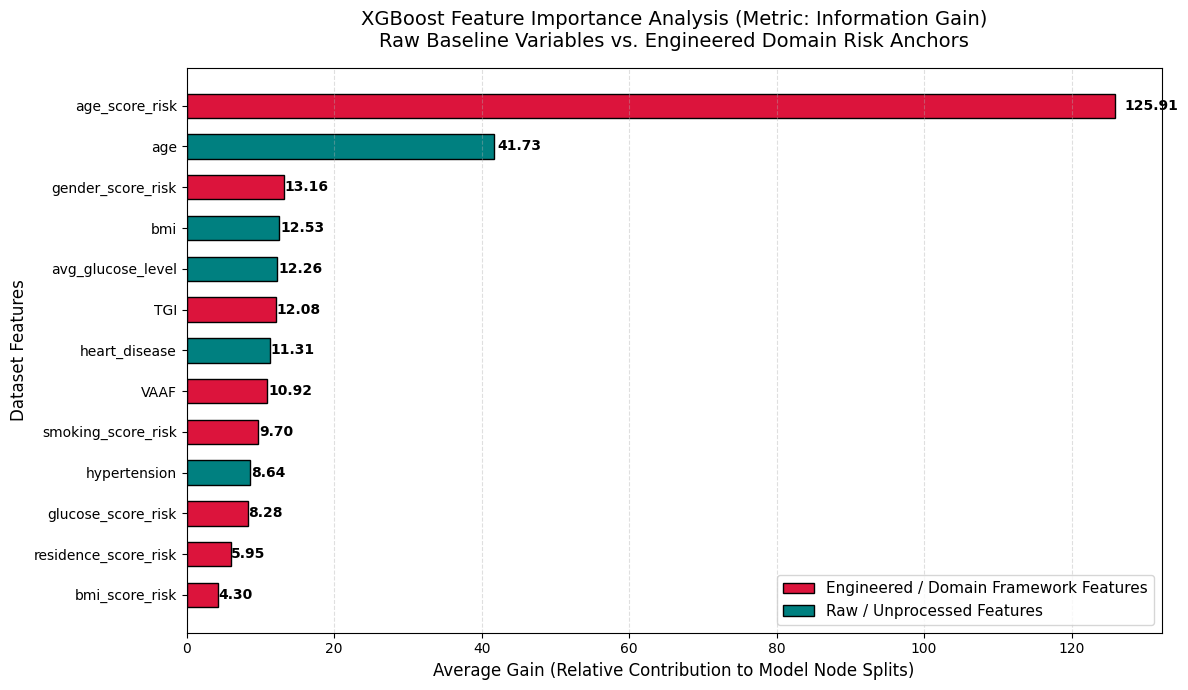

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from xgboost import XGBClassifier

df_final = pd.read_csv("Stroke_Prediction_Engineered2.csv")

all_features = [
    # --- Raw / Baseline Values ---
    'age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease',

    # --- Original Risk Score Anchors ---
    'gender_score_risk', 'age_score_risk', 'glucose_score_risk',
    'bmi_score_risk', 'smoking_score_risk', 'residence_score_risk',
    # --- NEW FEATURES ---
    'TGI',
    'VAAF'
]

X = df_final[all_features]
y = df_final['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Stage A: Bawasan ng bahagya ang No-Stroke Cases
under_sampler = RandomUnderSampler(sampling_strategy=0.1, random_state=42)
X_train_under, y_train_under = under_sampler.fit_resample(X_train, y_train)

over_sampler = RandomOverSampler(sampling_strategy=1.0, random_state=42)
X_train_hybrid, y_train_hybrid = over_sampler.fit_resample(X_train_under, y_train_under)

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.03,
    max_depth=3,
    subsample=0.7,
    colsample_bytree=0.7,
    eval_metric='logloss',
    random_state=42
)

# I-train ang model gamit ang pinag-isang data at bagong features
xgb_model.fit(X_train_hybrid, y_train_hybrid)

importance_gain = xgb_model.get_booster().get_score(importance_type='gain')

gain_df = pd.DataFrame({
    'Feature': list(importance_gain.keys()),
    'Gain_Score': list(importance_gain.values())
}).sort_values(by='Gain_Score', ascending=True)


def label_feature_type(row):
    if row['Feature'] in ['TGI', 'VAAF', 'glucose_score_risk', 'bmi_score_risk', 'age_score_risk', 'smoking_score_risk', 'gender_score_risk', 'residence_score_risk']:
        return 'Engineered Feature'
    return 'Raw / Baseline Value'

gain_df['Type'] = gain_df.apply(label_feature_type, axis=1)

plt.figure(figsize=(12, 7))

colors = ['crimson' if t == 'Engineered Feature' else 'teal' for t in gain_df['Type']]

bars = plt.barh(gain_df['Feature'], gain_df['Gain_Score'], color=colors, edgecolor='black', height=0.6)

for bar in bars:
    width = bar.get_width()
    plt.text(width + (width * 0.01), bar.get_y() + bar.get_height()/2, f'{width:.2f}',
             va='center', ha='left', fontsize=10, fontweight='bold', color='black')

plt.title('XGBoost Feature Importance Analysis (Metric: Information Gain)\nRaw Baseline Variables vs. Engineered Domain Risk Anchors', fontsize=14, pad=15)
plt.xlabel('Average Gain (Relative Contribution to Model Node Splits)', fontsize=12)
plt.ylabel('Dataset Features', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.4, axis='x')


from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='crimson', edgecolor='black', label='Engineered / Domain Framework Features'),
    Patch(facecolor='teal', edgecolor='black', label='Raw / Unprocessed Features')
]
plt.legend(handles=legend_elements, loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report


raw_features = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease']

engineered_features = ['age_score_risk', 'glucose_score_risk', 'bmi_score_risk',
                       'hypertension', 'heart_disease', 'smoking_score_risk', 'residence_score_risk',
                       'TGI', 'VAAF']

# Target variable
y = df_final['stroke']


X_raw = df_final[raw_features].dropna()
y_raw = df_final.loc[X_raw.index, 'stroke']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42, stratify=y_raw
)

model_raw = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model_raw.fit(X_train_r, y_train_r)

raw_preds_proba = model_raw.predict_proba(X_test_r)[:, 1]
raw_auc = roc_auc_score(y_test_r, raw_preds_proba)



X_eng = df_final[engineered_features].dropna()
y_eng = df_final.loc[X_eng.index, 'stroke']

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_eng, y_eng, test_size=0.2, random_state=42, stratify=y_eng
)

model_eng = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model_eng.fit(X_train_e, y_train_e)

eng_preds_proba = model_eng.predict_proba(X_test_e)[:, 1]
eng_auc = roc_auc_score(y_test_e, eng_preds_proba)


print("=" * 65)
print("       STANDALONE PREDICTIVE INDEPENDENT RELIABILITY REPORT      ")
print("=" * 65)
print(f"Framework A (Raw Features Only) Standalone AUC-ROC       : {raw_auc:.4f} ({raw_auc*100:.2f}%)")
print(f"Framework B (Engineered Tiers Only) Standalone AUC-ROC   : {eng_auc:.4f} ({eng_auc*100:.2f}%)")
print("-" * 65)
print(f"Absolute Predictive Variance (Loss from Compression)    : {raw_auc - eng_auc:+.4f}")
print("=" * 65)

print("\n[Detailed Classification Report - Raw Features Framework]")
print(classification_report(y_test_r, model_raw.predict(X_test_r)))

print("\n[Detailed Classification Report - Engineered Scores Framework]")
print(classification_report(y_test_e, model_eng.predict(X_test_e)))

       STANDALONE PREDICTIVE INDEPENDENT RELIABILITY REPORT      
Framework A (Raw Features Only) Standalone AUC-ROC       : 0.6698 (66.98%)
Framework B (Engineered Tiers Only) Standalone AUC-ROC   : 0.6630 (66.30%)
-----------------------------------------------------------------
Absolute Predictive Variance (Loss from Compression)    : +0.0068

[Detailed Classification Report - Raw Features Framework]
              precision    recall  f1-score   support

           0       0.95      0.70      0.80       604
           1       0.13      0.57      0.21        49

    accuracy                           0.69       653
   macro avg       0.54      0.63      0.51       653
weighted avg       0.89      0.69      0.76       653


[Detailed Classification Report - Engineered Scores Framework]
              precision    recall  f1-score   support

           0       0.96      0.55      0.70       604
           1       0.12      0.73      0.20        49

    accuracy                          

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

df = pd.read_csv('Stroke_Prediction_Engineered2.csv')


raw_features = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease']

engineered_features = ['age_score_risk', 'glucose_score_risk', 'bmi_score_risk',
                       'hypertension', 'heart_disease', 'smoking_score_risk', 'residence_score_risk',
                       'TGI', 'VAAF']


hybrid_features = ['age', 'avg_glucose_level', 'bmi',
                   'age_score_risk', 'glucose_score_risk', 'bmi_score_risk',
                   'hypertension', 'heart_disease', 'smoking_score_risk', 'residence_score_risk',
                   'TGI', 'VAAF']

def evaluate_framework(feature_list):
    X = df[feature_list].dropna()
    y = df.loc[X.index, 'stroke']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, class_weight='balanced')
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        "Overall Accuracy": f"{accuracy_score(y_test, predictions) * 100:.2f}%",
        "Stroke Sensitivity (Recall)": f"{recall_score(y_test, predictions) * 100:.2f}%",
        "AUC-ROC Discriminatory Power": f"{roc_auc_score(y_test, probabilities) * 100:.2f}%"
    }

results = {
    "1. Raw Only Framework": evaluate_framework(raw_features),
    "2. Engineered Only Framework": evaluate_framework(engineered_features),
    "3. Hybrid Approach Framework": evaluate_framework(hybrid_features)
}

performance_dashboard = pd.DataFrame(results).T
print("=" * 110)
print("                          PHILIPPINE STROKE PREDICTION MODEL PERFORMANCE           ")
print("=" * 110)
print(performance_dashboard.to_string())
print("=" * 110)

                          PHILIPPINE STROKE PREDICTION MODEL PERFORMANCE           
                             Overall Accuracy Stroke Sensitivity (Recall) AUC-ROC Discriminatory Power
1. Raw Only Framework                  73.66%                      38.78%                       67.49%
2. Engineered Only Framework           72.89%                      36.73%                       63.97%
3. Hybrid Approach Framework           75.04%                      42.86%                       66.99%
